In [1]:
import pandas as pd
df=pd.read_csv('water_potability.csv')
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [2]:
df.shape


(3276, 10)

In [3]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [4]:
df['Potability'].value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

In [7]:
df['ph'] = df['ph'].fillna(df['ph'].mean())
df['Sulfate'] = df['Sulfate'].fillna(df['Sulfate'].mean())
df['Trihalomethanes'] = df['Trihalomethanes'].fillna(df['Trihalomethanes'].mean())

df.isnull().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

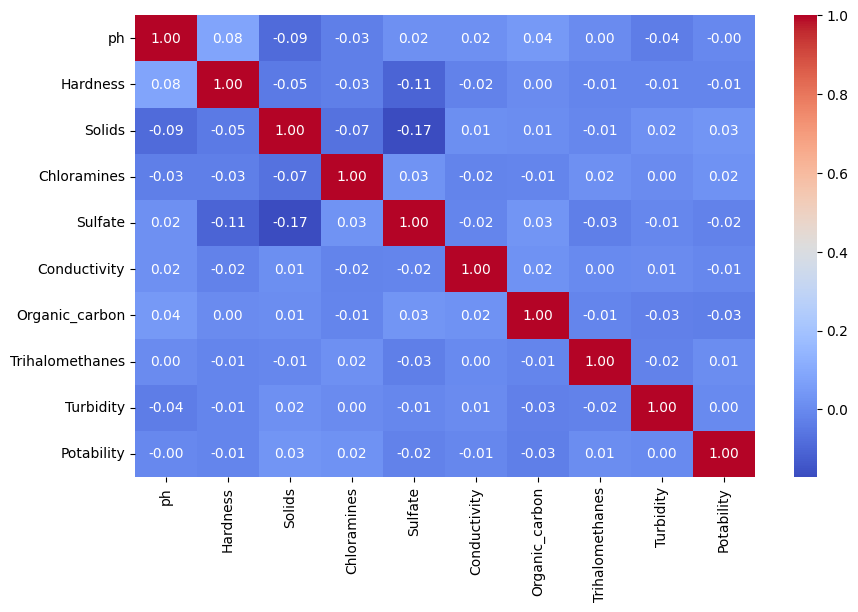

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

X = df.drop('Potability', axis=1)
y = df['Potability']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(2620, 9) (656, 9)


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6615853658536586
              precision    recall  f1-score   support

           0       0.67      0.89      0.76       400
           1       0.64      0.31      0.42       256

    accuracy                           0.66       656
   macro avg       0.65      0.60      0.59       656
weighted avg       0.66      0.66      0.63       656



In [11]:
import pandas as pd

importances = pd.Series(model.feature_importances_, index=X.columns)
importances.sort_values(ascending=False)

Sulfate            0.142040
ph                 0.134834
Hardness           0.117754
Chloramines        0.110991
Trihalomethanes    0.109442
Solids             0.106769
Conductivity       0.096892
Organic_carbon     0.091287
Turbidity          0.089992
dtype: float64

In [12]:
model2 = RandomForestClassifier(random_state=42, class_weight='balanced')
model2.fit(X_train, y_train)

y_pred2 = model2.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred2))
print(classification_report(y_test, y_pred2))

Accuracy: 0.6310975609756098
              precision    recall  f1-score   support

           0       0.67      0.80      0.72       400
           1       0.54      0.38      0.44       256

    accuracy                           0.63       656
   macro avg       0.60      0.58      0.58       656
weighted avg       0.62      0.63      0.61       656



In [13]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)

best_model = grid.best_estimator_
y_pred3 = best_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred3))
print(classification_report(y_test, y_pred3))

Best params: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}
Accuracy: 0.6692073170731707
              precision    recall  f1-score   support

           0       0.68      0.88      0.76       400
           1       0.64      0.34      0.45       256

    accuracy                           0.67       656
   macro avg       0.66      0.61      0.61       656
weighted avg       0.66      0.67      0.64       656



In [14]:
import joblib

joblib.dump(best_model, 'water_potability_model.pkl')

['water_potability_model.pkl']